# Consumer Complaint Classification — 10 Classical ML Algorithms vs. LoRA Fine-Tuning

**Task:** supervised multi-class text classification — predict the financial **Product** a consumer complaint is about.
**Data:** CFPB Consumer Complaint Database (Kaggle: `selener/consumer-complaint-database`, file `rows.csv`).
**Goal:** beat the Kaggle benchmark of **77.9 %** accuracy (LinearSVC, 5-fold CV, 10 000-row sample).

| | Kaggle benchmark | This notebook |
|---|---|---|
| Rows | 10 000 sampled | **all rows with a narrative** (80 % train / 20 % test) |
| Columns | 2 | **10** (9 inputs + the target) |
| Algorithms | 4 | **10 classical + LoRA-fine-tuned DistilBERT** |

### How to run
1. **Runtime → CPU + High-RAM** for Sections 0 → 6 (data, features, 10 classical models, tuning).
2. **Section 7 (LoRA)**: switch to a **GPU runtime (L4, or T4)**. The runtime restarts, so re-run only **Section 0 and Section 1** (setup + data + split) and then Section 7. Nothing else is needed — the classical results are saved on Drive.
3. **Section 8** reads every saved result and builds the final comparison. Needs Sections 0 and 1 only.
4. Everything important is saved to `MyDrive/ML_Project/` (`results/`, `features_cache/`, `lora_checkpoints/`). If Colab disconnects, re-run Sections 0–1 and carry on: finished models are skipped automatically (`RESUME = True`).
5. **First time:** set `QUICK_TEST = True` in the config cell and run everything once (a few minutes) to check that nothing breaks. Then set it back to `False`.

**Fairness rule:** every model is trained on the **same training rows** and scored on the **same test rows**. No model uses a subsample.

## 0. Setup

In [ ]:
   !pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [ ]:
# 0.1 — Install what Colab does not ship with (safe to re-run)
%pip install -q peft

In [ ]:
# 0.2 — Libraries
import os, sys, json, time, warnings, random, gc, re, inspect
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import scipy.sparse as sp
try:
    from IPython.display import display
except ImportError:
    display = print

In [ ]:
# 0.3 — Settings you can change (everything else follows from these)
# ============================ CONFIG (edit here) ============================
QUICK_TEST = False            # True = tiny smoke test (minutes). Run once to check, then set to False.
SEED            = 42
TEST_SIZE       = 0.20              # 80 % train / 20 % test
CLASS_MODE      = 'kaggle13'        # 'kaggle13' = same 13 classes as the Kaggle notebook (fair comparison); 'clean11' = 2 more overlaps merged
RESUME          = True              # skip models whose result file already exists on Drive
FORCE_RERUN     = []                # e.g. ['RandomForest'] to retrain one model
DROP_DUPLICATES = True              # remove complaints with the same text (after merging classes), before splitting (leak protection)
USE_CLASSIC_GB  = False             # True = also run sklearn GradientBoostingClassifier (can take many extra hours)
TUNE_MODELS     = ['LinearSVC', 'LogisticRegression']   # chosen a priori (strongest on sparse text); tuned with RandomizedSearchCV
LORA_MODEL      = 'distilbert-base-uncased'             # or 'bert-base-uncased'
LORA_TRAIN_ROWS = None              # None = ALL training rows (fair). A number = fewer rows (breaks fairness, prints a warning)
LORA_USE_META   = True              # prepend the metadata columns to the text fed to the transformer
BENCHMARK_ACC   = 0.779             # Kaggle: LinearSVC, 5-fold CV mean accuracy
# ===========================================================================

In [ ]:
# 0.4 — Size of the run: the quick test uses small values, the full run uses the real ones
if QUICK_TEST:
    P = dict(rows=30000, tfidf_max=20000, ohe_min_freq=20, svd=40, trees=20, ada=10, hgb=20, xgb=20,
             tune_n_iter={'LinearSVC': 2, 'LogisticRegression': 2}, tune_rows=5000, abl_rows=8000,
             lora_rows=1500, lora_epochs=1, lora_max_steps=20, lora_batch=16)
else:
    P = dict(rows=None, tfidf_max=300_000, ohe_min_freq=200, svd=300, trees=100, ada=100, hgb=300, xgb=300,
             tune_n_iter={'LinearSVC': 15, 'LogisticRegression': 8}, tune_rows=60_000, abl_rows=100_000,
             lora_rows=None, lora_epochs=2, lora_max_steps=-1, lora_batch=64)

In [ ]:
# 0.5 — Connect Google Drive (falls back to a local folder when not running in Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/ML_Project'); IN_COLAB = True
except ImportError:
    BASE = Path(os.environ.get('ML_PROJECT_DIR', './ML_Project')); IN_COLAB = False

Mounted at /content/drive


In [ ]:
# 0.6 — The folders where data and results live (the quick test uses its own folders, so it never mixes with the full run)
tag = '_quick' if QUICK_TEST else ''
CSV_PATH  = BASE / 'rows.csv'
RES_DIR   = BASE / f'results{tag}'
CACHE_DIR = BASE / f'features_cache{tag}'
CKPT_DIR  = BASE / f'lora_checkpoints{tag}'
ADAPTER_DIR = BASE / f'lora_adapter{tag}'
for d in (RES_DIR, CACHE_DIR): d.mkdir(parents=True, exist_ok=True)

In [ ]:
# 0.7 — Random seed (so results can be reproduced) and plot style
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    try:
        import torch; torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    except ImportError:
        pass
set_seed()
sns.set_theme(style='whitegrid')

In [ ]:
# 0.8 — Check the environment: Drive folder, run mode, GPU
print(f'Drive folder : {BASE}   (Colab: {IN_COLAB})')
print(f'Mode         : {"QUICK TEST" if QUICK_TEST else "FULL RUN"} | class mode: {CLASS_MODE}')
try:
    import torch
    print('GPU          :', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none (CPU runtime)')
except ImportError:
    print('GPU          : torch not installed')

Drive folder : /content/drive/MyDrive/ML_Project   (Colab: True)
Mode         : FULL RUN | class mode: kaggle13
GPU          : NVIDIA L4


In [ ]:
# 0.9 — Helpers (1/3): remember finished results and reuse them only if they were made with the same settings
RESULTS = {}      # finished results of this session
# FEAT_SIG / RUN_SIG / LORA_SIG (the settings a file was made with) are defined in Section 1, right after the train/test split.

def cached_ok(path, name, sig=None):
    # reuse a finished result from Drive only if it was produced with the same settings
    if not (RESUME and path.exists() and name not in FORCE_RERUN): return False
    r = json.load(open(path))
    if r.get('signature') != (sig or RUN_SIG):
        print(f'[stale] {name}: saved with different settings -> retraining'); return False
    RESULTS[name] = r; return True

def safe(name):
    return re.sub(r'[^A-Za-z0-9]+', '_', name).strip('_')

In [ ]:
# 0.10 — Helpers (2/3): metrics (accuracy, precision, recall, F1)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def score(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    return dict(accuracy=float(accuracy_score(y_true, y_pred)), precision_macro=float(p), recall_macro=float(r),
                f1_macro=float(f1), f1_weighted=float(precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)[2]))

In [ ]:
# 0.11 — Helpers (3/3): save a model's result and predictions to Drive
def save_result(name, y_pred, extra, sig=None):
    res = dict(model=name, signature=(sig or RUN_SIG), n_train=int(len(y_train)), n_test=int(len(y_test)))
    res.update(score(y_test, y_pred)); res.update(extra)
    np.save(RES_DIR / f'{safe(name)}_pred.npy', np.asarray(y_pred).astype(np.int16))
    json.dump(res, open(RES_DIR / f'{safe(name)}.json', 'w'), indent=1)
    RESULTS[name] = res
    return res

In [ ]:
# 0.12 — Helper: a stratified subset of rows (used by the tuning and ablation steps)
from sklearn.model_selection import train_test_split

def stratified_subset(n_wanted, y, seed=SEED):
    # indices of a stratified subset of n_wanted rows (all rows if n_wanted >= len(y))
    idx = np.arange(len(y))
    if n_wanted >= len(y): return idx
    return train_test_split(idx, train_size=n_wanted, stratify=y, random_state=seed)[0]

## 1. Data: inspect → clean → split
*Run this section every time (it is fast). It is the only thing Section 7 and Section 8 need from the classical part.*

**Columns used (10 of 18):** `Product` (target), `Consumer complaint narrative` (text) and 8 metadata inputs: `Company`, `State`, `Submitted via`, `Tags`, `Consumer consent provided?`, `Company response to consumer`, `Timely response?`, `Date received` (→ year, month).

**Deliberately left out:** `Sub-product`, `Issue`, `Sub-issue` (they almost give the answer away — label leakage), `Complaint ID` (just a counter), `ZIP code` (mostly masked), `Date sent to company`, `Company public response`, `Consumer disputed?` (little signal or only known after the fact).

**Order of work:** load the file → look at all 18 columns → filter → pick the 10 columns → clean → merge classes → split into train and test.

In [ ]:
# 1.1 — Pick the 10 columns we use (1 target + 1 text + 7 categorical + 1 date)
TARGET_COL = 'Product'
TEXT_COL   = 'Consumer complaint narrative'
CAT_RAW    = ['Company', 'State', 'Submitted via', 'Tags', 'Consumer consent provided?',
              'Company response to consumer', 'Timely response?']
DATE_COL   = 'Date received'
USE_COLS   = [TARGET_COL, TEXT_COL] + CAT_RAW + [DATE_COL]          # 10 columns
assert len(USE_COLS) == 10

In [ ]:
# 1.2 — Load the whole file (all 18 columns)
df_raw = pd.read_csv(CSV_PATH)
N_ROWS_BEFORE, N_COLS_TOTAL = df_raw.shape
print(f'Loaded {N_ROWS_BEFORE:,} rows and {N_COLS_TOTAL} columns')

/tmp/ipykernel_1529/1181450275.py:2: DtypeWarning: Columns (4,5,6,11,16) have mixed types. Specify dtype option on import or set low_memory=False.
  df_raw = pd.read_csv(CSV_PATH)


Loaded 1,282,355 rows and 18 columns


In [ ]:
# 1.3 — Shape of the raw data: (rows, columns)
print('Shape:', df_raw.shape)

Shape: (1282355, 18)


In [ ]:
# 1.4 — All the columns in the file
print(f'The file has {N_COLS_TOTAL} columns:\n')
for i, c in enumerate(df_raw.columns, 1):
    print(f'{i:>2}. {c}')

The file has 18 columns:

 1. Date received
 2. Product
 3. Sub-product
 4. Issue
 5. Sub-issue
 6. Consumer complaint narrative
 7. Company public response
 8. Company
 9. State
10. ZIP code
11. Tags
12. Consumer consent provided?
13. Submitted via
14. Date sent to company
15. Company response to consumer
16. Timely response?
17. Consumer disputed?
18. Complaint ID


In [ ]:
# 1.5 — First rows of the raw file (head)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 60)
display(df_raw.head())

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Consumer consent provided?,Submitted via,Date sent to company,Company response to consumer,Timely response?,Consumer disputed?,Complaint ID
0,05/10/2019,Checking or savings account,Checking account,Managing an account,Problem using a debit or ATM card,NaN,NaN,NAVY FEDERAL CREDIT UNION,FL,328XX,Older American,NaN,Web,05/10/2019,In progress,Yes,NaN,3238275
1,05/10/2019,Checking or savings account,Other banking product or service,Managing an account,Deposits and withdrawals,NaN,NaN,BOEING EMPLOYEES CREDIT UNION,WA,98204,NaN,NaN,Referral,05/10/2019,Closed with explanation,Yes,NaN,3238228
2,05/10/2019,Debt collection,Payday loan debt,Communication tactics,Frequent or repeated calls,NaN,NaN,CURO Intermediate Holdings,TX,751XX,NaN,NaN,Web,05/10/2019,Closed with explanation,Yes,NaN,3237964
3,05/10/2019,"Credit reporting, credit repair services, or other perso...",Credit reporting,Incorrect information on your report,Old information reappears or never goes away,NaN,NaN,Ad Astra Recovery Services Inc,LA,708XX,NaN,NaN,Web,05/10/2019,Closed with explanation,Yes,NaN,3238479
4,05/10/2019,Checking or savings account,Checking account,Managing an account,Banking errors,NaN,NaN,ALLY FINANCIAL INC.,AZ,85205,NaN,NaN,Postal mail,05/10/2019,In progress,Yes,NaN,3238460


In [ ]:
# 1.6 — Last rows (tail): the file is complete and not cut off
display(df_raw.tail())

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Consumer consent provided?,Submitted via,Date sent to company,Company response to consumer,Timely response?,Consumer disputed?,Complaint ID
1282350,12/01/2011,Credit card,NaN,Credit determination,NaN,NaN,NaN,"CITIBANK, N.A.",MO,63301,NaN,NaN,Web,12/02/2011,Closed with relief,Yes,No,2396
1282351,12/01/2011,Mortgage,Conventional fixed mortgage,"Loan modification,collection,foreclosure",NaN,NaN,NaN,"BANK OF AMERICA, NATIONAL ASSOCIATION",OH,45248,NaN,NaN,Web,12/06/2011,Closed without relief,No,No,2323
1282352,12/01/2011,Credit card,NaN,Billing disputes,NaN,NaN,NaN,JPMORGAN CHASE & CO.,OH,43207,NaN,NaN,Referral,12/01/2011,Closed with relief,Yes,No,2126
1282353,12/01/2011,Mortgage,Conventional adjustable mortgage (ARM),"Loan servicing, payments, escrow account",NaN,NaN,NaN,"BANK OF AMERICA, NATIONAL ASSOCIATION",CO,80920,NaN,NaN,Web,12/01/2011,Closed with relief,Yes,No,2315
1282354,12/01/2011,Credit card,NaN,Billing disputes,NaN,NaN,NaN,"CITIBANK, N.A.",WA,98275,NaN,NaN,Web,12/11/2011,Closed with relief,Yes,No,2329


In [ ]:
# 1.7 — Table info: non-null values and data type of every column (before filtering)
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1282355 entries, 0 to 1282354
Data columns (total 18 columns):
 #   Column                        Non-Null Count    Dtype 
---  ------                        --------------    ----- 
 0   Date received                 1282355 non-null  object
 1   Product                       1282355 non-null  object
 2   Sub-product                   1047189 non-null  object
 3   Issue                         1282355 non-null  object
 4   Sub-issue                     751169 non-null   object
 5   Consumer complaint narrative  383564 non-null   object
 6   Company public response       449082 non-null   object
 7   Company                       1282355 non-null  object
 8   State                         1262955 non-null  object
 9   ZIP code                      1167057 non-null  object
 10  Tags                          175643 non-null   object
 11  Consumer consent provided?    690654 non-null   object
 12  Submitted via                 1282355 non-

In [ ]:
# 1.8 — Missing values per column BEFORE filtering (this is why we filter: most complaints have no narrative)
miss = pd.DataFrame({'missing_rows': df_raw.isna().sum(), 'missing_%': (df_raw.isna().mean() * 100).round(1)})
display(miss.sort_values('missing_rows', ascending=False))

,missing_rows,missing_%
Tags,1106712,86.3
Consumer complaint narrative,898791,70.1
Company public response,833273,65.0
Consumer consent provided?,591701,46.1
Sub-issue,531186,41.4
Consumer disputed?,513854,40.1
Sub-product,235166,18.3
ZIP code,115298,9.0
State,19400,1.5
Company response to consumer,7,0.0


In [ ]:
# 1.9 — Filter: keep only the complaints that have a narrative (same rule as the Kaggle notebook)
df = df_raw[df_raw[TEXT_COL].notna()].copy()
N_ROWS_AFTER = len(df)
print(f'Rows before: {N_ROWS_BEFORE:,}   after: {N_ROWS_AFTER:,}')

Rows before: 1,282,355   after: 383,564


In [ ]:
# 1.10 — Keep a copy of the filtered text + label, only for reproducing the Kaggle benchmark in Section 4
bm_source = df[[TARGET_COL, TEXT_COL]].copy()

In [ ]:
# 1.11 — Used vs left out: all 18 columns with their role
role = {TARGET_COL: 'target', TEXT_COL: 'text input', DATE_COL: 'date input (-> year, month)'}
role.update({c: 'categorical input' for c in CAT_RAW})
cols_table = pd.DataFrame({'column': df_raw.columns,
                           'used?': ['YES' if c in USE_COLS else 'no' for c in df_raw.columns],
                           'role': [role.get(c, 'left out') for c in df_raw.columns]})
display(cols_table)
print(f'Columns in the file: {N_COLS_TOTAL}   |   used: {len(USE_COLS)}   |   left out: {N_COLS_TOTAL - len(USE_COLS)}')

,column,used?,role
0,Date received,YES,"date input (-> year, month)"
1,Product,YES,target
2,Sub-product,no,left out
3,Issue,no,left out
4,Sub-issue,no,left out
5,Consumer complaint narrative,YES,text input
6,Company public response,no,left out
7,Company,YES,categorical input
8,State,YES,categorical input
9,ZIP code,no,left out


Columns in the file: 18   |   used: 10   |   left out: 8


In [ ]:
# 1.12 — Keep only the 10 columns we use and free the memory of the raw file
df = df[USE_COLS].copy()
del df_raw; gc.collect()

103

In [ ]:
# 1.13 — The numbers for the presentation: rows and columns before and after filtering
print(f'Columns in the file       : {N_COLS_TOTAL}')
print(f'Columns used              : {len(USE_COLS)}  (9 inputs + target)')
print(f'Rows BEFORE filtering     : {N_ROWS_BEFORE:,}')
print(f'Rows AFTER  filtering     : {N_ROWS_AFTER:,}  ({N_ROWS_AFTER / N_ROWS_BEFORE:.1%} have a narrative)')

Columns in the file       : 18
Columns used              : 10  (9 inputs + target)
Rows BEFORE filtering     : 1,282,355
Rows AFTER  filtering     : 383,564  (29.9% have a narrative)


In [ ]:
# 1.14 — [quick test only] work with a small random sample so the whole notebook runs in minutes
if QUICK_TEST:
    df = df.sample(P['rows'], random_state=SEED).copy()
    print(f'[QUICK TEST] using only {len(df):,} rows')
else:
    print('Full run: all filtered rows are used')

Full run: all filtered rows are used


In [ ]:
# 1.15 — Convert the date text to real dates; count the ones that cannot be read
def parse_dates(s):
    d = pd.to_datetime(s, format='%m/%d/%Y', errors='coerce')
    if d.isna().mean() > 0.5:                      # file uses another date format -> let pandas infer it
        d = pd.to_datetime(s, errors='coerce')
    return d

dates = parse_dates(df[DATE_COL])
print(f'Dates that could not be read: {int(dates.isna().sum()):,}  (kept, with year = "missing")')
print('Date range:', dates.min().date(), '->', dates.max().date())

Dates that could not be read: 0  (kept, with year = "missing")
Date range: 2015-03-19 -> 2019-03-23


In [ ]:
# 1.16 — New columns: year and month of the complaint
df['year']  = dates.dt.year.astype('Int64').astype(str).replace('<NA>', 'missing')
df['month'] = dates.dt.month.astype('Int64').astype(str).replace('<NA>', 'missing')

In [ ]:
# 1.17 — Missing values in the metadata columns -> the text "missing" (so every row stays usable)
CAT_COLS = CAT_RAW + ['year', 'month']
for c in CAT_COLS:
    df[c] = df[c].fillna('missing').astype(str)
df[TEXT_COL] = df[TEXT_COL].astype(str)
df = df.reset_index(drop=True)

### Merging classes
*The Kaggle notebook merges 18 product names into 13 classes. We use the same merge so the comparison with its 77.9 % is fair.*

In [ ]:
# 1.18 — Class names to merge. Same merge as the Kaggle notebook (18 -> 13 classes) so the comparison is fair
KAGGLE13 = {
    'Credit reporting, credit repair services, or other personal consumer reports': 'Credit reporting, repair, or other',
    'Credit reporting': 'Credit reporting, repair, or other',
    'Credit card': 'Credit card or prepaid card',
    'Prepaid card': 'Credit card or prepaid card',
    'Payday loan': 'Payday loan, title loan, or personal loan',
    'Money transfer': 'Money transfer, virtual currency, or money service',
    'Virtual currency': 'Money transfer, virtual currency, or money service',
}
# Optional cleaner version: also merge the two overlaps the Kaggle notebook left behind.
EXTRA_CLEAN11 = {
    'Bank account or service': 'Checking or savings account',
    'Money transfers': 'Money transfer, virtual currency, or money service',
}
mapping = dict(KAGGLE13)
if CLASS_MODE == 'clean11':
    mapping.update(EXTRA_CLEAN11)

In [ ]:
# 1.19 — Apply the merge (the original name is kept in Product_raw)
df['Product_raw'] = df[TARGET_COL]
df['label_name']  = df[TARGET_COL].replace(mapping)

### Duplicates
*Removed AFTER the classes are merged: the same complaint text can sit under two old product names that become one class (e.g. "Credit reporting" and the newer long name). If one copy landed in train and the other in test, the model would be tested on a text it has already seen.*

In [ ]:
# 1.20 — Duplicates: how many complaints share the same text, and how many of those have conflicting classes?
n_dup_rows = int(df.duplicated().sum())
n_dup_text = int(df.duplicated(TEXT_COL).sum())
n_conflict = int((df.groupby(TEXT_COL)['label_name'].nunique() > 1).sum())
print(f'Identical rows (all columns)              : {n_dup_rows:,}')
print(f'Rows whose text already appeared before   : {n_dup_text:,}  ({n_dup_text / len(df):.3%} of the rows)')
print(f'Texts that appear under more than 1 class : {n_conflict:,}')

Identical rows (all columns)              : 1,462
Rows whose text already appeared before   : 16,619  (4.333% of the rows)
Texts that appear under more than 1 class : 147


In [ ]:
# 1.21 — Remove duplicates by complaint text (keep the first copy), so a test text can never also be in train
if DROP_DUPLICATES and n_dup_text:
    df = df.drop_duplicates(TEXT_COL, keep='first').reset_index(drop=True)
    print(f'Removed {n_dup_text:,} duplicates -> {len(df):,} rows remain')
else:
    print('No rows removed' + (' (DROP_DUPLICATES is False)' if not DROP_DUPLICATES else ' (no duplicates found)'))
N_ROWS_USED = len(df)

Removed 16,619 duplicates -> 366,945 rows remain


In [ ]:
# 1.22 — A class needs at least 2 rows to be split with stratification: drop the ones that do not
vc = df['label_name'].value_counts()
too_small = vc[vc < 2].index.tolist()
if too_small:
    print('Dropping classes with < 2 rows:', too_small)
    df = df[~df['label_name'].isin(too_small)].reset_index(drop=True)
else:
    print('Every class has at least 2 rows')

Every class has at least 2 rows


In [ ]:
# 1.23 — The classes after merging
print(f"Classes: {df['Product_raw'].nunique()} original -> {df['label_name'].nunique()} after merging ({CLASS_MODE})")
display(df['label_name'].value_counts().to_frame('rows'))

Classes: 18 original -> 13 after merging (kaggle13)


,rows
label_name,
"Credit reporting, repair, or other",110233
Debt collection,84277
Mortgage,52940
Credit card or prepaid card,41462
Student loan,21778
Bank account or service,14852
Checking or savings account,12857
Consumer Loan,9426
"Payday loan, title loan, or personal loan",6149


In [ ]:
# 1.24 — Turn class names into numbers
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

le = LabelEncoder().fit(df['label_name'])
class_names = list(le.classes_)
K = len(class_names)
y_all = le.transform(df['label_name'])

In [ ]:
# 1.25 — The ONE train/test split used by every model (80 % / 20 %, same class shares in both)
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=TEST_SIZE,
                                       stratify=y_all, random_state=SEED)
train_df = df.iloc[idx_train].reset_index(drop=True)
test_df  = df.iloc[idx_test].reset_index(drop=True)
y_train, y_test = y_all[idx_train], y_all[idx_test]

In [ ]:
# 1.26 — Check the split: sizes, and that both parts have the same class shares
print(f'Classes (K)     : {K}')
print(f'Train rows      : {len(train_df):,}   ({1 - TEST_SIZE:.0%})')
print(f'Test rows       : {len(test_df):,}   ({TEST_SIZE:.0%})')
display(pd.DataFrame({'train': pd.Series(y_train).value_counts(normalize=True).sort_index(),
                      'test':  pd.Series(y_test).value_counts(normalize=True).sort_index()}).set_index(pd.Index(class_names)).round(4))

Classes (K)     : 13
Train rows      : 293,556   (80%)
Test rows       : 73,389   (20%)


,train,test
Bank account or service,0.0405,0.0405
Checking or savings account,0.0350,0.0350
Consumer Loan,0.0257,0.0257
Credit card or prepaid card,0.1130,0.1130
"Credit reporting, repair, or other",0.3004,0.3004
Debt collection,0.2297,0.2297
"Money transfer, virtual currency, or money service",0.0149,0.0149
Money transfers,0.0041,0.0041
Mortgage,0.1443,0.1443
Other financial service,0.0008,0.0008


In [ ]:
# 1.27 — Leak check: how many test complaints have exactly the same text as a training complaint? (should be 0)
n_leak = int(test_df[TEXT_COL].isin(set(train_df[TEXT_COL])).sum())
print(f'Test complaints whose text also appears in the training set: {n_leak:,}')

Test complaints whose text also appears in the training set: 0


In [ ]:
# 1.28 — Run signatures: a saved file is reused only if it was made with exactly these settings
import hashlib
def make_sig(d):
    return hashlib.md5(json.dumps(d, sort_keys=True, default=str).encode()).hexdigest()[:12]

DATA_SETTINGS  = dict(class_mode=CLASS_MODE, seed=SEED, test_size=TEST_SIZE, drop_duplicates=DROP_DUPLICATES,
                      rows=P['rows'], n_train=int(len(y_train)), n_test=int(len(y_test)), n_classes=K)
FEAT_SETTINGS  = dict(DATA_SETTINGS, tfidf_max=P['tfidf_max'], ohe_min_freq=P['ohe_min_freq'], svd=P['svd'], abl_rows=P['abl_rows'])
MODEL_SETTINGS = dict(FEAT_SETTINGS, trees=P['trees'], ada=P['ada'], hgb=P['hgb'], xgb=P['xgb'], tune_rows=P['tune_rows'],
                      tune_n_iter=P['tune_n_iter'], tune_models=TUNE_MODELS, classic_gb=USE_CLASSIC_GB)
LORA_SETTINGS  = dict(DATA_SETTINGS, model=LORA_MODEL, use_meta=LORA_USE_META, train_rows=LORA_TRAIN_ROWS,
                      epochs=P['lora_epochs'], batch=P['lora_batch'], max_steps=P['lora_max_steps'], lr=2e-4, rank=16, max_len=256)
FEAT_SIG, RUN_SIG, LORA_SIG = make_sig(FEAT_SETTINGS), make_sig(MODEL_SETTINGS), make_sig(LORA_SETTINGS)
print(f'feature signature {FEAT_SIG} | classical-model signature {RUN_SIG} | LoRA signature {LORA_SIG}')

feature signature 2c20878c82e1 | classical-model signature 64513cadf247 | LoRA signature 498478c37eb0


## 2. Exploratory data analysis
*The raw-file inspection (head, tail, info, missing values, duplicates) is in Section 1. Here we study the cleaned data.*

In [ ]:
# 2.1 — Summary statistics of the text columns: number of distinct values, most frequent value and its count
display(df[[TARGET_COL] + CAT_RAW].describe().T)

,count,unique,top,freq
Product,366945,18,Debt collection,84277
Company,366945,4108,"EQUIFAX, INC.",33973
State,366945,64,CA,49797
Submitted via,366945,1,Web,366945
Tags,366945,4,missing,302566
Consumer consent provided?,366945,1,Consent provided,366945
Company response to consumer,366945,7,Closed with explanation,296370
Timely response?,366945,2,Yes,355829


In [ ]:
# 2.2 — Data type, missing share and number of distinct values of the 10 columns (after filtering)
overview = pd.DataFrame({'dtype': df[USE_COLS].dtypes.astype(str),
                         'missing_%': (df[USE_COLS].isna().mean() * 100).round(2),
                         'unique': df[USE_COLS].nunique()})
display(overview)

,dtype,missing_%,unique
Product,object,0.0,18
Consumer complaint narrative,object,0.0,366945
Company,object,0.0,4108
State,object,0.0,64
Submitted via,object,0.0,1
Tags,object,0.0,4
Consumer consent provided?,object,0.0,1
Company response to consumer,object,0.0,7
Timely response?,object,0.0,2
Date received,object,0.0,1464


In [ ]:
# 2.3 — How many "missing" values did we fill in each metadata column?
display((df[CAT_COLS] == 'missing').sum().to_frame('missing_rows'))

,missing_rows
Company,0
State,1366
Submitted via,0
Tags,302566
Consumer consent provided?,0
Company response to consumer,4
Timely response?,0
year,0
month,0


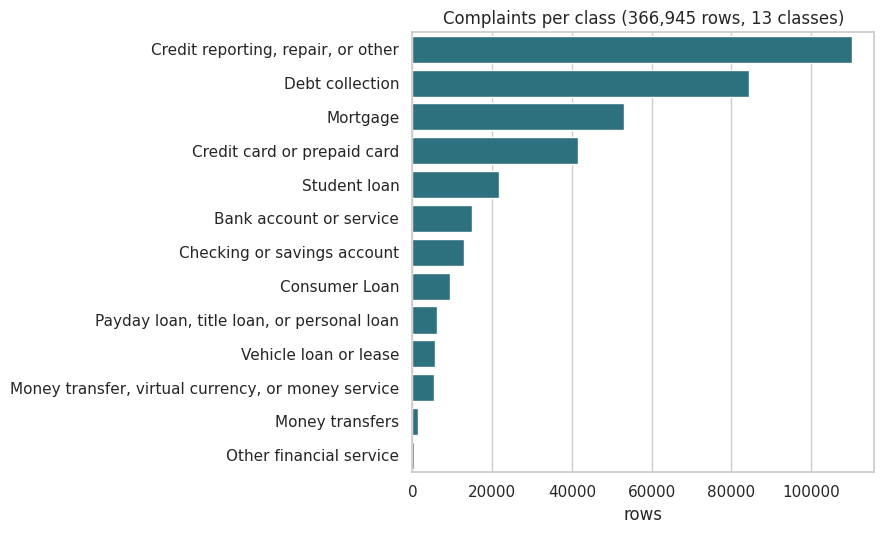

In [ ]:
# 2.4 — Class distribution (imbalance matters: accuracy hides weak small classes, so we also report macro-F1)
order = df['label_name'].value_counts().index
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.countplot(y='label_name', data=df, order=order, color='#1f7a8c', ax=ax)
ax.set_title(f'Complaints per class ({len(df):,} rows, {K} classes)'); ax.set_xlabel('rows'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

count    366945.0
mean        201.9
std         213.3
min           1.0
25%          75.0
50%         141.0
75%         255.0
max        6314.0


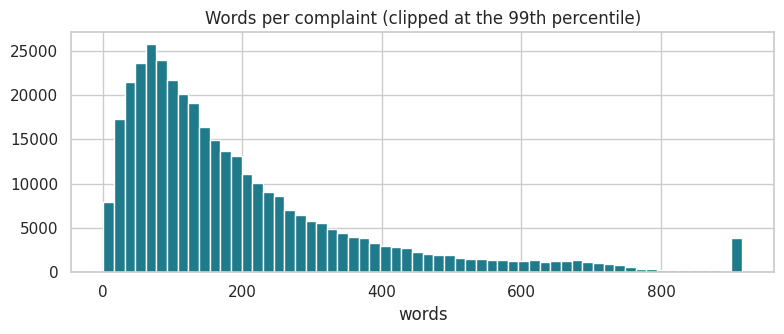

In [ ]:
# 2.5 — Length of the complaint text
words = df[TEXT_COL].str.split().str.len()
print(words.describe().round(1).to_string())
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(words.clip(upper=words.quantile(0.99)), bins=60, color='#1f7a8c')
ax.set_title('Words per complaint (clipped at the 99th percentile)'); ax.set_xlabel('words')
plt.tight_layout(); plt.show()

/tmp/ipykernel_17144/1774550330.py:8: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


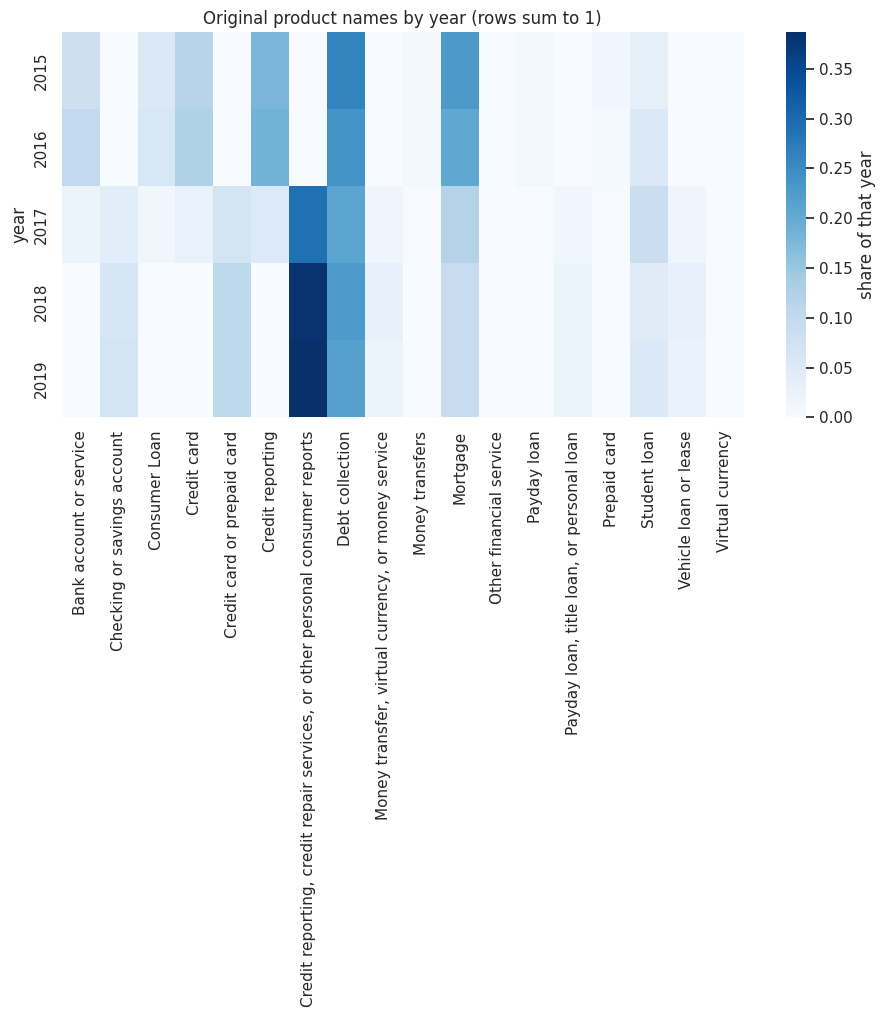

If a product name only exists in some years, `year` is a useful input column for the models.


In [ ]:
# 2.6 — Hypothesis: the complaint YEAR separates old and new product names
# (e.g. "Bank account or service" was replaced by "Checking or savings account", "Credit reporting" by a longer name).
ct = pd.crosstab(df['year'], df['Product_raw'])
ct_share = ct.div(ct.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(ct_share, cmap='Blues', ax=ax, cbar_kws={'label': 'share of that year'})
ax.set_title('Original product names by year (rows sum to 1)'); ax.set_xlabel(''); ax.set_ylabel('year')
plt.tight_layout(); plt.show()
print('If a product name only exists in some years, `year` is a useful input column for the models.')

In [ ]:
# 2.7 — The metadata columns: how many distinct values does each have?
display(df[CAT_COLS].nunique().to_frame('distinct_values').T)
print('Company has thousands of values: rare ones are grouped into one "infrequent" bucket in the one-hot encoder.')

,Company,State,Submitted via,Tags,Consumer consent provided?,Company response to consumer,Timely response?,year,month
distinct_values,4108,64,1,4,1,7,2,5,12


Company has thousands of values: rare ones are grouped into one "infrequent" bucket in the one-hot encoder.


## 3. Features (classical models)
Two blocks of features, both **fitted on the training rows only** (the Kaggle notebook fitted TF-IDF on all rows before cross-validating, which leaks a little):

* **Text** → TF-IDF with unigrams + bigrams (`sublinear_tf`, `min_df=5`, English stop words — the same settings as the benchmark; the vocabulary is capped at 300 000 terms to protect memory).
* **Metadata** → one-hot encoding of the 7 categorical columns + year + month (rare categories grouped).

The linear models and Naive Bayes use the sparse matrix. Trees, KNN, AdaBoost and XGBoost need a compact dense matrix, so they use the same rows reduced to 300 dimensions with truncated SVD (LSA). **The rows are identical; only the representation differs.**

In [ ]:
# 3.1 — Imports and the Drive files where the features are cached (so a disconnect does not cost you the TF-IDF step)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.decomposition import TruncatedSVD
from sklearn.svm import LinearSVC

def save_sp(path, m): sp.save_npz(path, m.tocsr(), compressed=False)
f = {k: CACHE_DIR / v for k, v in dict(Ttr='T_train.npz', Tte='T_test.npz', Mtr='M_train.npz', Mte='M_test.npz',
                                      meta='feat_meta.json', Ztr='Z_train.npy', Zte='Z_test.npy').items()}
FEATS_CACHED = RESUME and all(f[k].exists() for k in ('Ttr', 'Tte', 'Mtr', 'Mte', 'meta'))
if FEATS_CACHED and json.load(open(f['meta'])).get('sig') != FEAT_SIG:
    print('[stale] the cached features were made with other settings -> they will be rebuilt')
    FEATS_CACHED = False
print('Features already on Drive:', FEATS_CACHED)

Features already on Drive: False


In [ ]:
# 3.2 — Text -> numbers with TF-IDF (fitted on the training rows only)
if FEATS_CACHED:
    T_train, T_test = sp.load_npz(f['Ttr']), sp.load_npz(f['Tte'])
    print('[cached] text features loaded from Drive')
else:
    t0 = time.time()
    tfidf = TfidfVectorizer(sublinear_tf=True, min_df=5, ngram_range=(1, 2), stop_words='english',
                            max_features=P['tfidf_max'], dtype=np.float32)
    T_train = tfidf.fit_transform(train_df[TEXT_COL]); T_test = tfidf.transform(test_df[TEXT_COL])
    print(f'TF-IDF   : {T_train.shape[1]:,} text features ({time.time() - t0:.0f}s)')

TF-IDF   : 300,000 text features (122s)


In [ ]:
# 3.3 — Metadata columns -> numbers with one-hot encoding (fitted on the training rows only)
if FEATS_CACHED:
    M_train, M_test = sp.load_npz(f['Mtr']), sp.load_npz(f['Mte'])
    feat_meta = json.load(open(f['meta']))
    print('[cached] metadata features loaded from Drive')
else:
    ohe = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=P['ohe_min_freq'],
                        sparse_output=True, dtype=np.float32)
    M_train = ohe.fit_transform(train_df[CAT_COLS]); M_test = ohe.transform(test_df[CAT_COLS])
    print(f'One-hot  : {M_train.shape[1]:,} metadata features')

One-hot  : 237 metadata features


In [ ]:
# 3.4 — Save the two blocks to Drive
if not FEATS_CACHED:
    feat_meta = dict(sig=FEAT_SIG, n_text=int(T_train.shape[1]), n_meta=int(M_train.shape[1]))
    for k, m in (('Ttr', T_train), ('Tte', T_test), ('Mtr', M_train), ('Mte', M_test)): save_sp(f[k], m)
    json.dump(feat_meta, open(f['meta'], 'w')); print(f'saved to {CACHE_DIR}')
else:
    print('nothing to save (already cached)')

saved to /content/drive/MyDrive/ML_Project/features_cache


### Experiment A — do the metadata columns help, and how strongly should they count?
One-hot columns are 0/1 while TF-IDF values are small, so the metadata block gets a **weight** `w` (w = 0 means "text only"). We pick `w` with a **validation split carved out of the training rows** (the test set is never touched), using LinearSVC.

In [ ]:
# 3.5 — Experiment A: validation accuracy for 4 weights of the metadata block (validation rows come from the training set)
if 'ablation' in feat_meta and RESUME:
    abl = pd.DataFrame(feat_meta['ablation']); print('[cached]')
else:
    sub = stratified_subset(P['abl_rows'], y_train)
    a_tr, a_va = train_test_split(sub, test_size=0.2, stratify=y_train[sub], random_state=SEED)
    rows = []
    for w in [0.0, 0.25, 0.5, 1.0]:
        Xa = sp.hstack([T_train, M_train * w]).tocsr() if w > 0 else T_train
        m = LinearSVC(max_iter=2000).fit(Xa[a_tr], y_train[a_tr])
        rows.append((w, (m.predict(Xa[a_va]) == y_train[a_va]).mean()))
    abl = pd.DataFrame(rows, columns=['metadata_weight', 'validation_accuracy'])
display(abl.round(4))

,metadata_weight,validation_accuracy
0,0.00,0.8166
1,0.25,0.8732
2,0.50,0.8729
3,1.00,0.8731


In [ ]:
# 3.6 — Pick the weight with the best validation accuracy (the smaller one if tied) and save the choice
if 'meta_weight' in feat_meta and RESUME:
    META_WEIGHT = feat_meta['meta_weight']
else:
    best_gain = abl.validation_accuracy.max()
    META_WEIGHT = float(abl.loc[abl.validation_accuracy >= best_gain - 1e-9, 'metadata_weight'].min())
    feat_meta['meta_weight'] = META_WEIGHT; feat_meta['ablation'] = abl.to_dict('list')
    json.dump(feat_meta, open(f['meta'], 'w'))
gain = abl.validation_accuracy.max() - abl.loc[abl.metadata_weight == 0.0, 'validation_accuracy'].iloc[0]
print(f'Chosen META_WEIGHT = {META_WEIGHT}  (gain over text-only: {gain * 100:+.2f} points on validation)')

Chosen META_WEIGHT = 0.25  (gain over text-only: +5.65 points on validation)


In [ ]:
# 3.7 — Final sparse feature matrix = text block + weighted metadata block
X_train_sp = (sp.hstack([T_train, M_train * META_WEIGHT]) if META_WEIGHT > 0 else T_train).tocsr()
X_test_sp  = (sp.hstack([T_test,  M_test  * META_WEIGHT]) if META_WEIGHT > 0 else T_test).tocsr()
print('Sparse matrices:', X_train_sp.shape, X_test_sp.shape)

Sparse matrices: (293556, 300237) (73389, 300237)


In [ ]:
# 3.8 — Compact dense version for trees / KNN / AdaBoost / XGBoost (truncated SVD, fitted on train only)
if RESUME and f['Ztr'].exists() and f['Zte'].exists() and feat_meta.get('z_for') == [FEAT_SIG, META_WEIGHT]:
    Z_train, Z_test = np.load(f['Ztr']), np.load(f['Zte']); print('[cached] loaded SVD features')
else:
    t0 = time.time()
    svd = TruncatedSVD(n_components=P['svd'], n_iter=5, random_state=SEED)
    Z_train = svd.fit_transform(X_train_sp).astype(np.float32)
    Z_test  = svd.transform(X_test_sp).astype(np.float32)
    print(f'SVD: {P["svd"]} dims keep {svd.explained_variance_ratio_.sum():.1%} of the variance ({time.time() - t0:.0f}s)')
    np.save(f['Ztr'], Z_train); np.save(f['Zte'], Z_test)
    feat_meta['z_for'] = [FEAT_SIG, META_WEIGHT]; json.dump(feat_meta, open(f['meta'], 'w'))
FEATS = {'sparse': (X_train_sp, X_test_sp), 'svd': (Z_train, Z_test), 'text': (T_train.tocsr(), T_test.tocsr())}   # 'text' = no metadata (ablation)
print('Dense matrices :', Z_train.shape, Z_test.shape)

SVD: 300 dims keep 29.0% of the variance (178s)
Dense matrices : (293556, 300) (73389, 300)


## 4. Reproducing the Kaggle benchmark (sanity check)
The notebook we compare against: **10 000 random rows, 13 classes, TF-IDF (fitted on all 10 000), LinearSVC, 5-fold CV → 77.9 %**. We re-run exactly that, and also a leak-free version (TF-IDF fitted inside every fold), so our improvement is measured against the real number and not only against a quoted one.

In [ ]:
# 4.1 — Take the same 10 000-row sample as the Kaggle notebook (random_state=1) and merge classes the same way
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

bm_path = RES_DIR / 'benchmark_reproduction.json'
BM_CACHED = RESUME and bm_path.exists()
if not BM_CACHED:
    bm_df = bm_source.sample(min(10_000, len(bm_source)), random_state=1).copy()      # same rows as the Kaggle notebook
    bm_df['label'] = bm_df[TARGET_COL].replace(KAGGLE13).factorize()[0]
    kaggle_tfidf = dict(sublinear_tf=True, min_df=5, ngram_range=(1, 2), stop_words='english')
    print(f'{len(bm_df):,} rows, {bm_df.label.nunique()} classes')
else:
    print('[cached] benchmark reproduction already on Drive')

10,000 rows, 13 classes


In [ ]:
# 4.2 — Their protocol: TF-IDF fitted on all 10 000 rows first, then LinearSVC with 5-fold cross-validation
if not BM_CACHED:
    X_bm = TfidfVectorizer(**kaggle_tfidf).fit_transform(bm_df[TEXT_COL])      # sparse (Kaggle used .toarray(): same numbers)
    cv_kaggle = cross_val_score(LinearSVC(), X_bm, bm_df['label'], scoring='accuracy', cv=5)
    print('5 fold accuracies:', cv_kaggle.round(4))

5 fold accuracies: [0.7795 0.773  0.7785 0.788  0.7765]


In [ ]:
# 4.3 — Leak-free version: TF-IDF is re-fitted inside every fold, so the held-out fold never influences the vocabulary
if not BM_CACHED:
    cv_clean = cross_val_score(make_pipeline(TfidfVectorizer(**kaggle_tfidf), LinearSVC()),
                               bm_df[TEXT_COL], bm_df['label'], scoring='accuracy', cv=5)
    print('5 fold accuracies:', cv_clean.round(4))

5 fold accuracies: [0.774  0.773  0.7755 0.789  0.779 ]


In [ ]:
# 4.4 — Save and print the reproduced benchmark
if not BM_CACHED:
    bm = dict(rows=len(bm_df), kaggle_protocol_mean=float(cv_kaggle.mean()), kaggle_protocol_std=float(cv_kaggle.std(ddof=1)),
              leak_free_mean=float(cv_clean.mean()), leak_free_std=float(cv_clean.std(ddof=1)), quoted_benchmark=BENCHMARK_ACC)
    json.dump(bm, open(bm_path, 'w'), indent=1)
else:
    bm = json.load(open(bm_path))
print(f"Kaggle protocol (TF-IDF on all rows) : {bm['kaggle_protocol_mean']:.4f} ± {bm['kaggle_protocol_std']:.4f}   (quoted: {BENCHMARK_ACC})")
print(f"Leak-free (TF-IDF inside each fold)  : {bm['leak_free_mean']:.4f} ± {bm['leak_free_std']:.4f}")

Kaggle protocol (TF-IDF on all rows) : 0.7791 ± 0.0056   (quoted: 0.779)
Leak-free (TF-IDF inside each fold)  : 0.7781 ± 0.0065


## 5. The ten classical algorithms
Every model gets the **same train rows and the same test rows**. A small helper trains the model, scores it on the test set, saves the result + predictions to Drive and skips models that are already done — so a disconnect never costs you finished work.

In [ ]:
# 5.1 — Helper that trains one model, scores it on the test rows, saves everything to Drive and skips finished models
# (RESULTS / cached_ok / score / save_result are defined at the end of Section 1)
def run_model(name, estimator, feat, note=''):
    jp = RES_DIR / f'{safe(name)}.json'
    if cached_ok(jp, name):
        print(f"[cached] {name:<28} accuracy {RESULTS[name]['accuracy']:.4f}"); return RESULTS[name]
    Xtr, Xte = FEATS[feat]
    print(f'training {name} on {Xtr.shape[0]:,} rows ({feat} features) ...')
    t0 = time.time(); estimator.fit(Xtr, y_train); t_fit = time.time() - t0
    t0 = time.time(); y_pred = estimator.predict(Xte); t_pred = time.time() - t0
    res = save_result(name, y_pred, dict(features=feat, train_seconds=round(t_fit, 1), predict_seconds=round(t_pred, 1), note=note))
    print(f"-> {name}: accuracy {res['accuracy']:.4f} | macro-F1 {res['f1_macro']:.4f} | train {t_fit:.0f}s, predict {t_pred:.0f}s")
    return res

### Linear models and Naive Bayes (sparse TF-IDF + metadata)

In [ ]:
# 5.2 — Logistic Regression
from sklearn.linear_model import LogisticRegression
run_model('LogisticRegression', LogisticRegression(max_iter=300, random_state=SEED), 'sparse')

training LogisticRegression on 293,556 rows (sparse features) ...
-> LogisticRegression: accuracy 0.8854 | macro-F1 0.7439 | train 763s, predict 0s


{'model': 'LogisticRegression',
 'signature': '64513cadf247',
 'n_train': 293556,
 'n_test': 73389,
 'accuracy': 0.8853642916513373,
 'precision_macro': 0.7742622992504599,
 'recall_macro': 0.7214537893922739,
 'f1_macro': 0.7438558580845804,
 'f1_weighted': 0.8837395746148494,
 'features': 'sparse',
 'train_seconds': 762.9,
 'predict_seconds': 0.3,
 'note': ''}

In [ ]:
# 5.3 — Multinomial Naive Bayes
from sklearn.naive_bayes import MultinomialNB
run_model('MultinomialNB', MultinomialNB(), 'sparse')

training MultinomialNB on 293,556 rows (sparse features) ...
-> MultinomialNB: accuracy 0.7580 | macro-F1 0.3582 | train 1s, predict 0s


{'model': 'MultinomialNB',
 'signature': '64513cadf247',
 'n_train': 293556,
 'n_test': 73389,
 'accuracy': 0.7579746283502977,
 'precision_macro': 0.7345279056473514,
 'recall_macro': 0.3568183788544876,
 'f1_macro': 0.3582499936236519,
 'f1_weighted': 0.71182081051226,
 'features': 'sparse',
 'train_seconds': 1.0,
 'predict_seconds': 0.3,
 'note': ''}

In [ ]:
# 5.4 — Linear SVC (the model that won the Kaggle benchmark)
run_model('LinearSVC', LinearSVC(max_iter=2000, random_state=SEED), 'sparse', note='the Kaggle benchmark model, here with more data + metadata')

training LinearSVC on 293,556 rows (sparse features) ...
-> LinearSVC: accuracy 0.8836 | macro-F1 0.7499 | train 68s, predict 0s


{'model': 'LinearSVC',
 'signature': '64513cadf247',
 'n_train': 293556,
 'n_test': 73389,
 'accuracy': 0.8835792829988145,
 'precision_macro': 0.8413480646554832,
 'recall_macro': 0.7270326610388952,
 'f1_macro': 0.7499348435485719,
 'f1_weighted': 0.8821320709777992,
 'features': 'sparse',
 'train_seconds': 67.5,
 'predict_seconds': 0.2,
 'note': 'the Kaggle benchmark model, here with more data + metadata'}

In [ ]:
# 5.5 — Ablation: the same LinearSVC on the same rows, but with the text only (no metadata columns)
run_model('LinearSVC (text only)', LinearSVC(max_iter=2000, random_state=SEED), 'text',
          note='ablation: same model and rows as LinearSVC, text only -> shows how much of the gain comes from the metadata columns')

training LinearSVC (text only) on 293,556 rows (text features) ...
-> LinearSVC (text only): accuracy 0.8352 | macro-F1 0.6524 | train 67s, predict 0s


{'model': 'LinearSVC (text only)',
 'signature': '64513cadf247',
 'n_train': 293556,
 'n_test': 73389,
 'accuracy': 0.8351796590769733,
 'precision_macro': 0.7584319679600705,
 'recall_macro': 0.6211757692901122,
 'f1_macro': 0.6524260143543061,
 'f1_weighted': 0.8308398698601225,
 'features': 'text',
 'train_seconds': 66.6,
 'predict_seconds': 0.3,
 'note': 'ablation: same model and rows as LinearSVC, text only -> shows how much of the gain comes from the metadata columns'}

### Tree models, KNN, boosting (dense SVD features)

In [ ]:
# 5.6 — Decision Tree
from sklearn.tree import DecisionTreeClassifier
run_model('DecisionTree', DecisionTreeClassifier(random_state=SEED), 'svd')

training DecisionTree on 293,556 rows (svd features) ...
-> DecisionTree: accuracy 0.7013 | macro-F1 0.4799 | train 920s, predict 0s


{'model': 'DecisionTree',
 'signature': '64513cadf247',
 'n_train': 293556,
 'n_test': 73389,
 'accuracy': 0.7012767580972625,
 'precision_macro': 0.47677847110873783,
 'recall_macro': 0.48351680133435243,
 'f1_macro': 0.4799206077555036,
 'f1_weighted': 0.7020768965729667,
 'features': 'svd',
 'train_seconds': 919.7,
 'predict_seconds': 0.1,
 'note': ''}

In [ ]:
# 5.7 — Random Forest
from sklearn.ensemble import RandomForestClassifier
run_model('RandomForest', RandomForestClassifier(n_estimators=P['trees'], n_jobs=-1, random_state=SEED), 'svd',
          note='no depth limit (the Kaggle notebook capped depth at 5, which made it underfit)')

training RandomForest on 293,556 rows (svd features) ...
-> RandomForest: accuracy 0.8262 | macro-F1 0.6003 | train 383s, predict 1s


{'model': 'RandomForest',
 'signature': '64513cadf247',
 'n_train': 293556,
 'n_test': 73389,
 'accuracy': 0.8261592336726212,
 'precision_macro': 0.754333126620597,
 'recall_macro': 0.5581187245895183,
 'f1_macro': 0.6003422697031724,
 'f1_weighted': 0.8163060308122714,
 'features': 'svd',
 'train_seconds': 383.2,
 'predict_seconds': 0.8,
 'note': 'no depth limit (the Kaggle notebook capped depth at 5, which made it underfit)'}

In [ ]:
# 5.8 — Extra Trees
from sklearn.ensemble import ExtraTreesClassifier
run_model('ExtraTrees', ExtraTreesClassifier(n_estimators=P['trees'], n_jobs=-1, random_state=SEED), 'svd')

training ExtraTrees on 293,556 rows (svd features) ...
-> ExtraTrees: accuracy 0.8161 | macro-F1 0.5793 | train 53s, predict 1s


{'model': 'ExtraTrees',
 'signature': '64513cadf247',
 'n_train': 293556,
 'n_test': 73389,
 'accuracy': 0.8160759786889044,
 'precision_macro': 0.7609406167149747,
 'recall_macro': 0.5350874691538631,
 'f1_macro': 0.5793403306115861,
 'f1_weighted': 0.8033846733143006,
 'features': 'svd',
 'train_seconds': 53.0,
 'predict_seconds': 1.2,
 'note': ''}

In [ ]:
# 5.9 — K-Nearest Neighbours
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import Normalizer
# Rows are L2-normalised first, so Euclidean distance behaves like cosine distance (better for text vectors).
run_model('KNN', make_pipeline(Normalizer(), KNeighborsClassifier(n_neighbors=5, algorithm='brute', n_jobs=-1)), 'svd')

training KNN on 293,556 rows (svd features) ...
-> KNN: accuracy 0.7096 | macro-F1 0.4863 | train 0s, predict 145s


{'model': 'KNN',
 'signature': '64513cadf247',
 'n_train': 293556,
 'n_test': 73389,
 'accuracy': 0.709643134529698,
 'precision_macro': 0.5215366818630597,
 'recall_macro': 0.4737627072490683,
 'f1_macro': 0.48626208158104295,
 'f1_weighted': 0.7069772330597932,
 'features': 'svd',
 'train_seconds': 0.4,
 'predict_seconds': 145.3,
 'note': ''}

In [ ]:
# 5.10 — AdaBoost
from sklearn.ensemble import AdaBoostClassifier
run_model('AdaBoost', AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3), n_estimators=P['ada'],
                                         learning_rate=1.0, random_state=SEED), 'svd',
          note='uses every training row; single-threaded, so it is the slowest classical model')

training AdaBoost on 293,556 rows (svd features) ...
-> AdaBoost: accuracy 0.6983 | macro-F1 0.5066 | train 9414s, predict 2s


{'model': 'AdaBoost',
 'signature': '64513cadf247',
 'n_train': 293556,
 'n_test': 73389,
 'accuracy': 0.6983062856831406,
 'precision_macro': 0.5772213056513037,
 'recall_macro': 0.47822941832878274,
 'f1_macro': 0.5065538998468452,
 'f1_weighted': 0.6954761788612746,
 'features': 'svd',
 'train_seconds': 9414.1,
 'predict_seconds': 2.4,
 'note': 'uses every training row; single-threaded, so it is the slowest classical model'}

### Gradient boosting (two fast implementations)
`GradientBoostingClassifier` from scikit-learn needs hours on this many rows, so **Gradient Boosting** is run with scikit-learn's histogram-based version (`HistGradientBoostingClassifier`) — the same algorithm, built for large data. XGBoost is the second boosting library. Set `USE_CLASSIC_GB = True` in the config to also run the classic one.

In [ ]:
# 5.11 — Gradient Boosting (histogram-based version of scikit-learn)
from sklearn.ensemble import HistGradientBoostingClassifier
run_model('GradientBoosting', HistGradientBoostingClassifier(max_iter=P['hgb'], learning_rate=0.1, early_stopping=True,
                                                             validation_fraction=0.1, n_iter_no_change=10, random_state=SEED),
          'svd', note='HistGradientBoostingClassifier (histogram-based gradient boosting)')

training GradientBoosting on 293,556 rows (svd features) ...
-> GradientBoosting: accuracy 0.8261 | macro-F1 0.6384 | train 61s, predict 3s


{'model': 'GradientBoosting',
 'signature': '64513cadf247',
 'n_train': 293556,
 'n_test': 73389,
 'accuracy': 0.8261183556118764,
 'precision_macro': 0.6678136040442783,
 'recall_macro': 0.625049623889435,
 'f1_macro': 0.6384463883306413,
 'f1_weighted': 0.8247867504286535,
 'features': 'svd',
 'train_seconds': 60.6,
 'predict_seconds': 3.1,
 'note': 'HistGradientBoostingClassifier (histogram-based gradient boosting)'}

In [ ]:
# 5.12 — (optional) the classic scikit-learn GradientBoostingClassifier; only runs if USE_CLASSIC_GB = True
if USE_CLASSIC_GB:
    from sklearn.ensemble import GradientBoostingClassifier
    run_model('GradientBoosting_classic', GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=SEED), 'svd')

In [ ]:
# 5.13 — XGBoost
try:
    from xgboost import XGBClassifier
    try:
        import torch; dev = 'cuda' if torch.cuda.is_available() else 'cpu'
    except ImportError:
        dev = 'cpu'
    run_model('XGBoost', XGBClassifier(n_estimators=P['xgb'], max_depth=6, learning_rate=0.1, tree_method='hist', device=dev,
                                       n_jobs=-1, random_state=SEED), 'svd', note=f'device={dev}')
except ImportError:
    print('xgboost is not installed in this environment -> skipped (it is pre-installed on Colab)')

training XGBoost on 293,556 rows (svd features) ...
-> XGBoost: accuracy 0.8654 | macro-F1 0.7127 | train 597s, predict 2s


## 6. Hyperparameter tuning (RandomizedSearchCV)
The two models tuned are fixed in advance (`TUNE_MODELS`): **LinearSVC** and **Logistic Regression**, the strongest families on sparse text. The search uses 3-fold cross-validation on a stratified part of the **training** rows only; the best settings are then refit on **all** training rows and scored on the test set **once**. (Choosing the models to tune from test scores would leak the test set, so we do not do that.)

In [ ]:
# 6.1 — What to tune: the settings and the range of values to try for each model
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone
from scipy.stats import loguniform

TUNE_SPACE = {
    'LinearSVC':          (LinearSVC(max_iter=3000, random_state=SEED), {'C': loguniform(0.05, 5),  'class_weight': [None, 'balanced']}),
    'LogisticRegression': (LogisticRegression(max_iter=200, random_state=SEED), {'C': loguniform(1, 100), 'class_weight': [None, 'balanced']}),
}

In [ ]:
# 6.2 — Random search with 3-fold CV on part of the training rows, then refit the best settings on ALL training rows
Xtr_sp = FEATS['sparse'][0]
for name in TUNE_MODELS:
    tuned = f'{name} (tuned)'
    if cached_ok(RES_DIR / f'{safe(tuned)}.json', tuned):
        print(f"[cached] {tuned:<28} accuracy {RESULTS[tuned]['accuracy']:.4f}"); continue
    est, space = TUNE_SPACE[name]
    sub = stratified_subset(P['tune_rows'], y_train)
    print(f'tuning {name}: {P["tune_n_iter"][name]} random settings x 3 folds on {len(sub):,} training rows ...')
    t0 = time.time()
    search = RandomizedSearchCV(est, space, n_iter=P['tune_n_iter'][name], cv=3, scoring='accuracy',
                                n_jobs=-1, random_state=SEED, refit=False)
    search.fit(Xtr_sp[sub], y_train[sub])
    pd.DataFrame(search.cv_results_).sort_values('rank_test_score').to_csv(RES_DIR / f'tuning_{safe(name)}.csv', index=False)
    print(f'  best CV accuracy {search.best_score_:.4f} with {dict((k, (round(float(v), 4) if isinstance(v, (int, float, np.floating)) else v)) for k, v in search.best_params_.items())}  ({time.time() - t0:.0f}s)')
    run_model(tuned, clone(est).set_params(**search.best_params_), 'sparse', note='best params: ' + str({k: (round(float(v), 4) if isinstance(v, (int, float, np.floating)) else v) for k, v in search.best_params_.items()}))

tuning LinearSVC: 15 random settings x 3 folds on 60,000 training rows ...
  best CV accuracy 0.8715 with {'C': 0.8361, 'class_weight': None}  (94s)
training LinearSVC (tuned) on 293,556 rows (sparse features) ...
-> LinearSVC (tuned): accuracy 0.8841 | macro-F1 0.7458 | train 65s, predict 0s
tuning LogisticRegression: 8 random settings x 3 folds on 60,000 training rows ...
  best CV accuracy 0.8717 with {'C': 15.7513, 'class_weight': None}  (868s)
training LogisticRegression (tuned) on 293,556 rows (sparse features) ...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


-> LogisticRegression (tuned): accuracy 0.8798 | macro-F1 0.7584 | train 763s, predict 0s


## 7. LoRA fine-tuning of DistilBERT
**What LoRA does:** instead of updating all ~66 M weights of DistilBERT, we freeze them and learn small low-rank matrices (rank 16) added to the attention *query* and *value* layers, plus the classification head. That is about 1–2 % of the parameters, so it trains faster and needs far less GPU memory, yet it adapts the pretrained language model to this task.

**Needs a GPU runtime** (L4 or T4). After switching, re-run **Section 0 and Section 1** first. Checkpoints go to Drive every 1 000 steps, so a disconnect resumes from the last checkpoint when you re-run the training cell.

In [ ]:
# [LORA] 7.1 — Imports and GPU check
import torch
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding)
from transformers.trainer_utils import get_last_checkpoint
from peft import LoraConfig, get_peft_model, TaskType

HAS_GPU = torch.cuda.is_available()
if not HAS_GPU and not QUICK_TEST:
    raise RuntimeError('No GPU. Runtime -> Change runtime type -> L4 (or T4) GPU, then re-run Sections 0-1 and this cell.')
print('GPU:', torch.cuda.get_device_name(0) if HAS_GPU else 'none (quick test on CPU)')

GPU: NVIDIA L4


In [ ]:
# [LORA] 7.2 — Settings, and check whether this model was already trained and saved on Drive
LORA_NAME = {'distilbert-base-uncased': 'LoRA_DistilBERT', 'bert-base-uncased': 'LoRA_BERT'}.get(LORA_MODEL, 'LoRA_' + safe(LORA_MODEL))
LORA_PATH = RES_DIR / f'{safe(LORA_NAME)}.json'
LORA_DONE = cached_ok(LORA_PATH, LORA_NAME, LORA_SIG)
if LORA_DONE:
    print(f"[cached] {LORA_NAME}: accuracy {RESULTS[LORA_NAME]['accuracy']:.4f} -> skipping tokenisation and training")
LORA_FAMILY = 'distilbert' if 'distilbert' in LORA_MODEL else 'bert'
LORA_TARGETS = {'distilbert': dict(target=['q_lin', 'v_lin'], save=['pre_classifier', 'classifier']),   # attention query / value layers
                'bert':       dict(target=['query', 'value'], save=['classifier'])}[LORA_FAMILY]
MAX_LEN = 256

In [ ]:
# [LORA] 7.3 — Which training rows to use (all of them, unless you changed LORA_TRAIN_ROWS) and load the tokenizer
if not LORA_DONE:
    n_use = P['lora_rows'] if QUICK_TEST else LORA_TRAIN_ROWS
    if n_use and n_use < len(train_df):
        sub = stratified_subset(n_use, y_train)
        l_train, y_l = train_df.iloc[sub].reset_index(drop=True), y_train[sub]
        print(f'WARNING: LoRA uses only {len(l_train):,} of {len(train_df):,} training rows -> not the same data as the other models.')
    else:
        l_train, y_l = train_df, y_train
    tok = AutoTokenizer.from_pretrained(LORA_MODEL)
    print(f'LoRA training rows: {len(l_train):,} | test rows: {len(test_df):,}')

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

LoRA training rows: 293,556 | test rows: 73,389


In [ ]:
# [LORA] 7.4 — Text fed to the model: the metadata columns as a short first sentence, the complaint as the second
if not LORA_DONE:
    def meta_text(d):
        return (d['Company'].str[:40] + ' | ' + d['State'] + ' | ' + d['Submitted via'] + ' | ' + d['Tags'].str[:25] + ' | ' +
                d['Consumer consent provided?'] + ' | ' + d['Company response to consumer'].str[:40] + ' | timely: ' +
                d['Timely response?'] + ' | ' + d['year'] + '-' + d['month']).tolist()

    def encode(d, bs=5000):
        text = d[TEXT_COL].tolist(); meta = meta_text(d) if LORA_USE_META else None
        ids = []
        for i in range(0, len(text), bs):
            if meta is not None:   # sentence pair: (metadata, narrative); only the narrative is truncated
                enc = tok(meta[i:i + bs], text[i:i + bs], truncation='only_second', max_length=MAX_LEN)
            else:
                enc = tok(text[i:i + bs], truncation=True, max_length=MAX_LEN)
            ids.extend(np.asarray(x, dtype=np.int32) for x in enc['input_ids'])
        return ids
    print('example input:', meta_text(l_train.head(1))[0][:120], '||', l_train[TEXT_COL].iloc[0][:80], '...')

example input: AES/PHEAA | AL | Web | missing | Consent provided | Closed with explanation | timely: Yes | 2017-11 || Hi to whomever in concern, This is a goodwill request to remove the late payment ...


In [ ]:
# [LORA] 7.5 — Turn all texts into token ids (words -> numbers the transformer understands)
if not LORA_DONE:
    t0 = time.time(); ids_train = encode(l_train); ids_test = encode(test_df)
    lens = np.array([len(x) for x in ids_train])
    print(f'Tokenised {len(ids_train):,} train + {len(ids_test):,} test texts in {time.time() - t0:.0f}s')
    print(f'Median length {np.median(lens):.0f} tokens; {np.mean(lens >= MAX_LEN):.1%} of the training texts are cut at {MAX_LEN} tokens')

Tokenised 293,556 train + 73,389 test texts in 64s
Median length 207 tokens; 39.4% of the training texts are cut at 256 tokens


In [ ]:
# [LORA] 7.6 — A small dataset wrapper so the Hugging Face Trainer can read the token ids
if not LORA_DONE:
    class ComplaintDS(torch.utils.data.Dataset):
        def __init__(self, ids, labels): self.ids, self.labels = ids, labels
        def __len__(self): return len(self.ids)
        def __getitem__(self, i):
            x = self.ids[i].tolist()
            return {'input_ids': x, 'attention_mask': [1] * len(x), 'labels': int(self.labels[i])}
    train_ds, test_ds = ComplaintDS(ids_train, y_l), ComplaintDS(ids_test, y_test)

In [ ]:
# [LORA] 7.7 — Load DistilBERT and attach the LoRA adapters (rank 16) to the attention layers
if not LORA_DONE:
    base = AutoModelForSequenceClassification.from_pretrained(
        LORA_MODEL, num_labels=K, id2label=dict(enumerate(class_names)), label2id={c: i for i, c in enumerate(class_names)})
    lora_cfg = LoraConfig(task_type=TaskType.SEQ_CLS, r=16, lora_alpha=32, lora_dropout=0.1, bias='none',
                          target_modules=LORA_TARGETS['target'], modules_to_save=LORA_TARGETS['save'])
    model = get_peft_model(base, lora_cfg)
    model.print_trainable_parameters()

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 895,501 || all params: 67,858,970 || trainable%: 1.3197


In [ ]:
# [LORA] 7.8 — Precision: bf16 on L4/A100, fp16 on T4, fp32 on CPU
if not LORA_DONE:
    use_bf16 = HAS_GPU and torch.cuda.get_device_capability()[0] >= 8      # L4/A100: bf16; T4: fp16
    print('precision:', 'bf16' if use_bf16 else ('fp16' if HAS_GPU else 'fp32 (CPU)'))

precision: bf16


In [ ]:
# [LORA] 7.9 — Training settings (checkpoints are saved to Drive every 1 000 steps)
if not LORA_DONE:
    ta_kwargs = dict(output_dir=str(CKPT_DIR), per_device_train_batch_size=P['lora_batch'], per_device_eval_batch_size=128,
                     learning_rate=2e-4, num_train_epochs=P['lora_epochs'], weight_decay=0.01,
                     lr_scheduler_type='linear', logging_steps=100, save_strategy='steps', save_steps=1000, save_total_limit=2,
                     seed=SEED, report_to='none', dataloader_num_workers=2,
                     bf16=use_bf16, fp16=(HAS_GPU and not use_bf16), max_steps=P['lora_max_steps'])
    valid = set(inspect.signature(TrainingArguments.__init__).parameters)
    # Options that were renamed between transformers versions (warm-up ratio, batches of similar length = less padding).
    if 'warmup_ratio' in valid: ta_kwargs['warmup_ratio'] = 0.06
    else: ta_kwargs['warmup_steps'] = 0.06                      # newer versions: a float < 1 means a ratio
    if 'group_by_length' in valid: ta_kwargs['group_by_length'] = True
    elif 'train_sampling_strategy' in valid: ta_kwargs['train_sampling_strategy'] = 'group_by_length'
    dropped = sorted(k for k in ta_kwargs if k not in valid)
    if dropped: print('TrainingArguments options not supported by this transformers version (ignored):', dropped)
    args = TrainingArguments(**{k: v for k, v in ta_kwargs.items() if k in valid})

In [ ]:
# [LORA] 7.10 — The Trainer
if not LORA_DONE:
    tok_kw = {'processing_class': tok} if 'processing_class' in inspect.signature(Trainer.__init__).parameters else {'tokenizer': tok}
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, data_collator=DataCollatorWithPadding(tok), **tok_kw)

In [ ]:
# [LORA] 7.11 — Checkpoints on Drive: resume only if they were made with the same LoRA settings, otherwise move them aside
if not LORA_DONE:
    import shutil
    sig_file = CKPT_DIR / 'lora_signature.txt'
    if CKPT_DIR.exists() and any(CKPT_DIR.glob('checkpoint-*')) and (not sig_file.exists() or sig_file.read_text().strip() != LORA_SIG):
        old = CKPT_DIR.with_name(CKPT_DIR.name + f'_old_{int(time.time())}')
        shutil.move(str(CKPT_DIR), str(old)); print(f'[stale] checkpoints were made with other settings -> moved to {old.name}')
    CKPT_DIR.mkdir(parents=True, exist_ok=True); sig_file.write_text(LORA_SIG)

In [ ]:
# [LORA] 7.12 — TRAIN (resumes from the last checkpoint on Drive if the session was interrupted)
if not LORA_DONE:
    last = get_last_checkpoint(str(CKPT_DIR)) if CKPT_DIR.exists() else None
    print('Resuming from checkpoint:', last) if last else print('Starting a fresh training run')
    t0 = time.time(); trainer.train(resume_from_checkpoint=last); t_fit = time.time() - t0
    print(f'training finished in {t_fit / 60:.1f} min (this session)')

Starting a fresh training run


Step,Training Loss
100,2.365100
200,1.890444
300,1.115029
400,0.762525
500,0.719211
600,0.655011
700,0.577462
800,0.536464
900,0.526404
1000,0.501870


training finished in 19.8 min (this session)


In [ ]:
# [LORA] 7.13 — Predict the SAME test rows as the other models, save the result and the LoRA adapter to Drive
if not LORA_DONE:
    t0 = time.time(); out = trainer.predict(test_ds); t_pred = time.time() - t0
    y_pred_lora = out.predictions.argmax(-1)
    res = save_result(LORA_NAME, y_pred_lora, dict(features='text+metadata tokens' if LORA_USE_META else 'text tokens',
            train_seconds=round(t_fit, 1), predict_seconds=round(t_pred, 1), n_train=int(len(y_l)),
            note=f'{LORA_MODEL}, r=16, alpha=32, epochs={P["lora_epochs"]}, max_len={MAX_LEN}; train time = this session only (a resumed run is longer in total)'),
            sig=LORA_SIG)
    model.save_pretrained(str(ADAPTER_DIR))
    print(f"-> {LORA_NAME}: accuracy {res['accuracy']:.4f} | macro-F1 {res['f1_macro']:.4f} | train {t_fit / 60:.0f} min")

-> LoRA_DistilBERT: accuracy 0.1834 | macro-F1 0.0764 | train 20 min


In [ ]:
from torch.utils.data import DataLoader
t0 = time.time()
model.eval()
dl = DataLoader(test_ds, batch_size=128, shuffle=False, collate_fn=DataCollatorWithPadding(tok))
dev = next(model.parameters()).device
preds = []
with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16 if use_bf16 else torch.float16, enabled=HAS_GPU):
    for b in dl:
        b = {k: v.to(dev) for k, v in b.items() if k != 'labels'}
        preds.append(model(**b).logits.argmax(-1).cpu())
y_pred_lora = torch.cat(preds).numpy(); t_pred = time.time() - t0
res = save_result(LORA_NAME, y_pred_lora, dict(features='text+metadata tokens' if LORA_USE_META else 'text tokens',
        train_seconds=round(t_fit, 1), predict_seconds=round(t_pred, 1), n_train=int(len(y_l)),
        note=f'{LORA_MODEL}, r=16, alpha=32, epochs={P["lora_epochs"]}, max_len={MAX_LEN}; predictions in original test order'),
        sig=LORA_SIG)
model.save_pretrained(str(ADAPTER_DIR))
print(f"-> {LORA_NAME}: accuracy {res['accuracy']:.4f} | macro-F1 {res['f1_macro']:.4f}")

-> LoRA_DistilBERT: accuracy 0.8893 | macro-F1 0.7632


## 8. Final comparison against the Kaggle benchmark
*Needs only Sections 0 and 1 in the current session (it reads every saved result from Drive).*

In [ ]:
# 8.1 — Collect every saved result into one table (sorted by accuracy)
from sklearn.metrics import classification_report, confusion_matrix
bm = json.load(open(RES_DIR / 'benchmark_reproduction.json'))     # written by Section 4
rows = []
for p in sorted(RES_DIR.glob('*.json')):
    r = json.load(open(p))
    if 'model' in r and 'accuracy' in r and r.get('signature') in (RUN_SIG, LORA_SIG): rows.append(r)
res_df = pd.DataFrame(rows).sort_values('accuracy', ascending=False).reset_index(drop=True)
res_df['vs_benchmark_pts'] = ((res_df['accuracy'] - BENCHMARK_ACC) * 100).round(2)
cols = ['model', 'accuracy', 'f1_macro', 'f1_weighted', 'precision_macro', 'recall_macro', 'vs_benchmark_pts', 'train_seconds', 'predict_seconds', 'features']

In [ ]:
# 8.2 — Show the results table
display(res_df[cols].round(4))

,model,accuracy,f1_macro,f1_weighted,precision_macro,recall_macro,vs_benchmark_pts,train_seconds,predict_seconds,features
0,LoRA_DistilBERT,0.8893,0.7632,0.8886,0.8479,0.7533,11.03,1190.4,87.6,text+metadata tokens
1,LogisticRegression,0.8854,0.7439,0.8837,0.7743,0.7215,10.64,762.9,0.3,sparse
2,LinearSVC (tuned),0.8841,0.7458,0.8826,0.8427,0.7248,10.51,65.2,0.4,sparse
3,LinearSVC,0.8836,0.7499,0.8821,0.8413,0.7270,10.46,67.5,0.2,sparse
4,LogisticRegression (tuned),0.8798,0.7584,0.8790,0.8164,0.7398,10.08,762.8,0.4,sparse
5,XGBoost,0.8654,0.7127,0.8634,0.8187,0.6893,8.64,597.2,2.2,svd
6,LinearSVC (text only),0.8352,0.6524,0.8308,0.7584,0.6212,5.62,66.6,0.3,text
7,RandomForest,0.8262,0.6003,0.8163,0.7543,0.5581,4.72,383.2,0.8,svd
8,GradientBoosting,0.8261,0.6384,0.8248,0.6678,0.6250,4.71,60.6,3.1,svd
9,ExtraTrees,0.8161,0.5793,0.8034,0.7609,0.5351,3.71,53.0,1.2,svd


In [ ]:
# 8.3 — Save the table as a CSV file on Drive
res_df[cols].to_csv(RES_DIR / 'results_summary.csv', index=False)

In [ ]:
# 8.4 — Where does the improvement come from? LinearSVC with and without the metadata columns, on the same train/test rows
lin = res_df.set_index('model')['accuracy']
if 'LinearSVC (text only)' in lin and 'LinearSVC' in lin:
    print(f"Kaggle benchmark (10K rows, 5-fold CV) : {BENCHMARK_ACC:.4f}")
    print(f"LinearSVC, text only, our split        : {lin['LinearSVC (text only)']:.4f}   ({(lin['LinearSVC (text only)'] - BENCHMARK_ACC) * 100:+.2f} pts vs benchmark: more training data)")
    print(f"LinearSVC, text + metadata             : {lin['LinearSVC']:.4f}   ({(lin['LinearSVC'] - lin['LinearSVC (text only)']) * 100:+.2f} pts from the metadata columns)")

Kaggle benchmark (10K rows, 5-fold CV) : 0.7790
LinearSVC, text only, our split        : 0.8352   (+5.62 pts vs benchmark: more training data)
LinearSVC, text + metadata             : 0.8836   (+4.84 pts from the metadata columns)


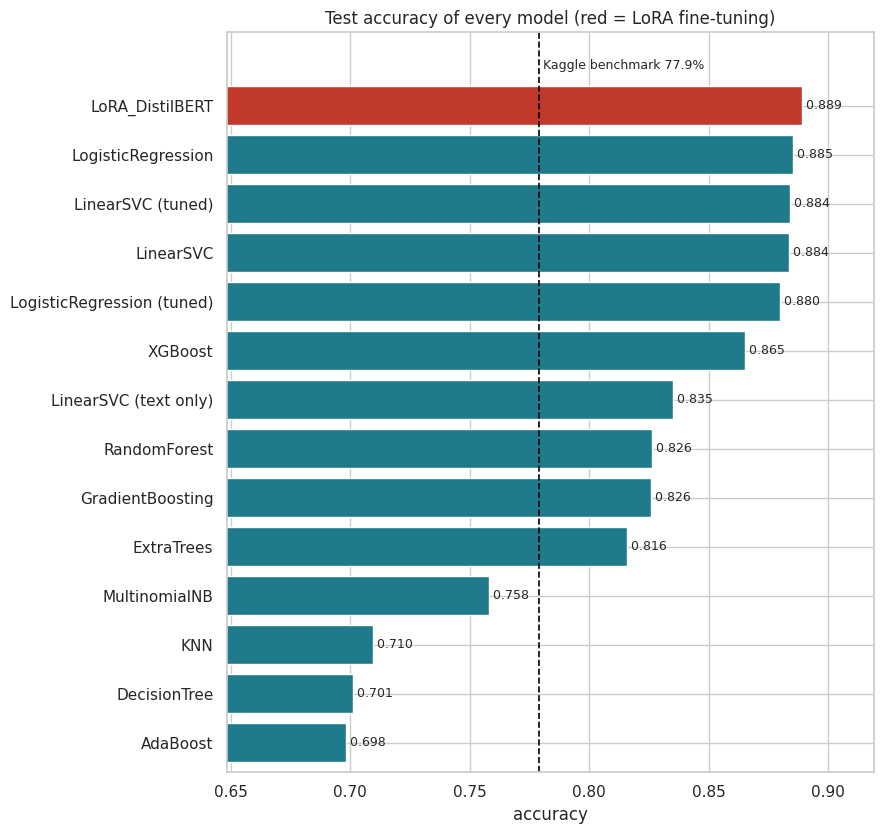

In [ ]:
# 8.5 — Bar chart: every model against the Kaggle benchmark
fig, ax = plt.subplots(figsize=(9, 0.5 * len(res_df) + 1.5))
colors = ['#c0392b' if m.startswith('LoRA') else '#1f7a8c' for m in res_df['model']]
ax.barh(res_df['model'][::-1], res_df['accuracy'][::-1], color=colors[::-1])
ax.axvline(BENCHMARK_ACC, color='black', ls='--', lw=1.2); ax.set_ylim(-0.6, len(res_df) + 0.5)
ax.text(BENCHMARK_ACC, len(res_df) - 0.3, f' Kaggle benchmark {BENCHMARK_ACC:.1%}', va='bottom', fontsize=9)
ax.set_xlim(max(0, res_df['accuracy'].min() - 0.05), min(1, res_df['accuracy'].max() + 0.03))
for i, v in enumerate(res_df['accuracy'][::-1]): ax.text(v, i, f' {v:.3f}', va='center', fontsize=9)
ax.set_title('Test accuracy of every model (red = LoRA fine-tuning)'); ax.set_xlabel('accuracy')
plt.tight_layout(); plt.show()

In [ ]:
# 8.6 — The best model and its predictions on the test set
is_ablation = res_df['model'].str.contains('text only')
best = res_df[~is_ablation].iloc[0]; best_name = best['model']     # the text-only row is an experiment, not a candidate
y_best = np.load(RES_DIR / f'{safe(best_name)}_pred.npy')
base_names = {re.sub(r' \(tuned\)$', '', m) for m in res_df['model'] if not m.startswith('LoRA') and 'classic' not in m and 'text only' not in m}
n_classical = len(base_names)

In [ ]:
# 8.7 — The numbers for the presentation (rows, columns, algorithms, best accuracy vs. the benchmark)
print('=' * 66)
print(f'Rows before filtering : {N_ROWS_BEFORE:,}')
print(f'Rows after filtering  : {N_ROWS_AFTER:,}')
print(f'Rows used (no duplicates): {N_ROWS_USED:,}   (train {len(y_train):,} / test {len(y_test):,})')
print(f'Columns               : {N_COLS_TOTAL} in the file, 10 used (9 inputs + target)')
print(f'Algorithms            : {n_classical} classical + LoRA fine-tuned transformer ({res_df["model"].str.startswith("LoRA").sum()} run)')
print(f'Best model            : {best_name}  ->  accuracy {best["accuracy"]:.4f}, macro-F1 {best["f1_macro"]:.4f}')
print(f'Kaggle benchmark      : {BENCHMARK_ACC:.3f}   ->  difference {best["vs_benchmark_pts"]:+.2f} points')
print(f'Kaggle reproduced here: {bm["kaggle_protocol_mean"]:.4f} (their protocol) | {bm["leak_free_mean"]:.4f} (leak-free)')
print('Result:', 'BEATS the benchmark' if best['accuracy'] > BENCHMARK_ACC else 'does NOT beat the benchmark')
print('=' * 66)

Rows before filtering : 1,282,355
Rows after filtering  : 383,564
Rows used (no duplicates): 366,945   (train 293,556 / test 73,389)
Columns               : 18 in the file, 10 used (9 inputs + target)
Algorithms            : 10 classical + LoRA fine-tuned transformer (1 run)
Best model            : LoRA_DistilBERT  ->  accuracy 0.8893, macro-F1 0.7632
Kaggle benchmark      : 0.779   ->  difference +11.03 points
Kaggle reproduced here: 0.7791 (their protocol) | 0.7781 (leak-free)
Result: BEATS the benchmark


In [ ]:
# 8.8 — Save the final numbers to Drive
json.dump(dict(rows_before=N_ROWS_BEFORE, rows_after=N_ROWS_AFTER, rows_used=N_ROWS_USED, n_train=int(len(y_train)), n_test=int(len(y_test)),
               columns_in_file=N_COLS_TOTAL, columns_used=10, classical_algorithms=n_classical, best_model=best_name,
               best_accuracy=float(best['accuracy']), benchmark=BENCHMARK_ACC, class_mode=CLASS_MODE, quick_test=QUICK_TEST),
          open(RES_DIR / 'final_summary.json', 'w'), indent=1)

In [ ]:
# 8.9 — Precision / recall / F1 for each class, best model
print(f'Per-class report - {best_name}\n')
print(classification_report(y_test, y_best, target_names=class_names, digits=3, zero_division=0))

Per-class report - LoRA_DistilBERT

                                                    precision    recall  f1-score   support

                           Bank account or service      0.853     0.823     0.838      2970
                       Checking or savings account      0.821     0.843     0.832      2572
                                     Consumer Loan      0.799     0.738     0.767      1885
                       Credit card or prepaid card      0.834     0.882     0.857      8292
                Credit reporting, repair, or other      0.939     0.912     0.925     22047
                                   Debt collection      0.877     0.888     0.883     16855
Money transfer, virtual currency, or money service      0.878     0.785     0.829      1094
                                   Money transfers      0.777     0.689     0.730       299
                                          Mortgage      0.929     0.960     0.944     10588
                           Other financial 

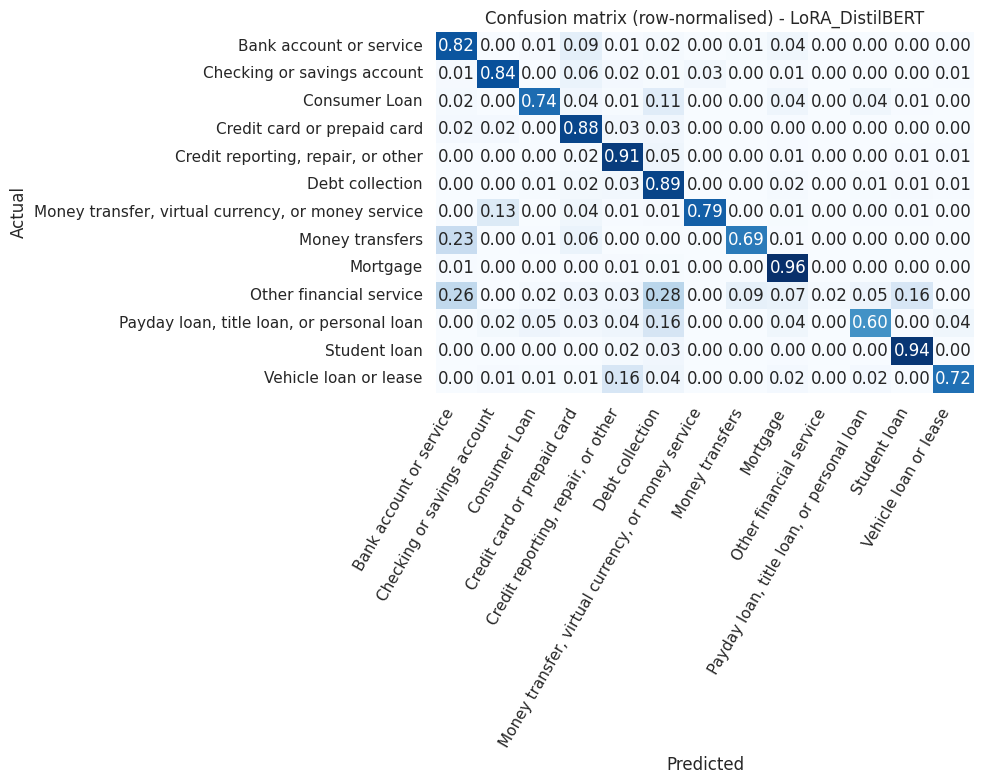

In [ ]:
# 8.10 — Confusion matrix of the best model (each row sums to 1: where do the complaints of a class end up?)
cm = confusion_matrix(y_test, y_best)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax, cbar=False)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(f'Confusion matrix (row-normalised) - {best_name}')
plt.xticks(rotation=60, ha='right'); plt.tight_layout(); plt.show()

In [ ]:
# 8.11 — Error analysis: the most frequent confusions, with real examples
off = [(cm[a, b], a, b) for a in range(K) for b in range(K) if a != b]
for n, a, b in [t for t in sorted(off, reverse=True)[:6] if t[0] > 0]:
    print(f"\n'{class_names[a]}'  predicted as  '{class_names[b]}' : {n} complaints")
    ex = test_df[(y_test == a) & (y_best == b)].head(2)
    for _, r in ex.iterrows(): print('   -', r[TEXT_COL][:260].replace('\n', ' '), '...')


'Credit reporting, repair, or other'  predicted as  'Debt collection' : 1004 complaints
   - I have contacted the company and they did nothing about it. CREDIT MANAGEMENT LP XX/XX/XXXX XXXX XXXX XXXX XXXX, TX XXXX CREDIT MANAGEMENT - {$390.00} XX/XX/XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX, MN XXXX - {$1000.00} XX/XX/XXXX XXXX XXXX XXXX XXXX {$100 ...
   - I have been reported by Credit Collection Services for over two years ( XX/XX/XXXX ), I sent a letter by certified mail on XX/XX/XXXX, in order to obtain information of this report as the information reported is inaccurate. I spoke with a representative over t ...

'Debt collection'  predicted as  'Credit reporting, repair, or other' : 522 complaints
   - I have an account reporting on my credit that is not mines. I have never used these services before nor have I giving anyone else permission on my behalf. The information stated in the account is bogus and has no relation to me. ...
   - I went to XXXX XXXX  located at XXXX XXX

,accuracy,rows
year,,
2015,0.915,10753
2016,0.909,15375
2017,0.889,21846
2018,0.867,22176
2019,0.865,3239


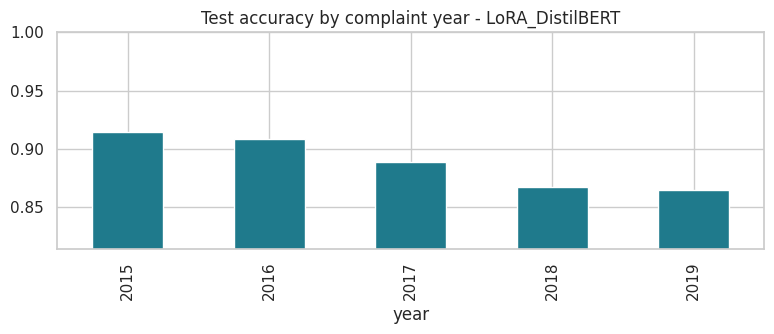

In [ ]:
# 8.12 — Does the year matter? Accuracy of the best model per year (old vs new product names)
yr = pd.DataFrame({'year': test_df['year'], 'correct': (y_best == y_test)})
by_year = yr.groupby('year')['correct'].agg(['mean', 'size']).rename(columns={'mean': 'accuracy', 'size': 'rows'})
by_year = by_year[by_year.rows >= 50]
display(by_year.round(3))
fig, ax = plt.subplots(figsize=(8, 3.5)); by_year['accuracy'].plot.bar(ax=ax, color='#1f7a8c')
ax.set_ylim(by_year['accuracy'].min() - 0.05, 1); ax.set_title(f'Test accuracy by complaint year - {best_name}'); plt.tight_layout(); plt.show()

In [ ]:
# 8.13 — A few example predictions (so the numbers are interpretable)
smp = test_df.sample(6, random_state=SEED)
for i, r in smp.iterrows():
    print(f"TRUE: {class_names[y_test[i]]}\nPRED: {class_names[y_best[i]]}  {'OK' if y_test[i] == y_best[i] else 'WRONG'}\nTEXT: {r[TEXT_COL][:220]}...\n")

TRUE: Consumer Loan
PRED: Consumer Loan  OK
TEXT: I bought a car and was making payments when I lost my job. I fell behind. The car was repossessed and sold. I owed {$13000.00}. The car was sold for {$8900.00}. 
Westlake Financial Services sent this to a collection agen...

TRUE: Checking or savings account
PRED: Checking or savings account  OK
TEXT: I went online to download 7 years of transactions, following a message from Chase, describing how to download such transactions. However the list showing the download availability shows only up through XXXX, and 7 years ...

TRUE: Debt collection
PRED: Debt collection  OK
TEXT: Commonwealth Financial Systems has once again placed an unsubstantiated collection on my credit reports in the amount of {$57.00}. This is the 6th time that this fraudulent account has appeared on my credit reports and t...

TRUE: Credit card or prepaid card
PRED: Credit card or prepaid card  OK
TEXT: On  X/XX/2017   , I spoke with  XXXX   XXXX   ( USBank ,  XXXX   

## 9. Conclusion (fill in after the full run)
* **Best model and accuracy:** see the table in Section 8 — compare it with the Kaggle benchmark (77.9 %).
* **Why it can beat the benchmark:** ~38× more training rows, features fitted on training data only, metadata columns, a tuned LinearSVC and a fine-tuned transformer.
* **Remaining weaknesses:** small classes (low macro-F1) and classes that overlap by definition, such as *Bank account or service* vs *Checking or savings account*.
* **Next steps:** merge the overlapping classes (`CLASS_MODE = 'clean11'`), try `bert-base-uncased`, tune LoRA (rank, learning rate, epochs), and use class weights for the small classes.